# Nội dung 1 – Thu thập và tiền xử lý dữ liệu TNBC (TCGA-BRCA, METABRIC)

**Đề tài:** Mô hình tiên lượng tái phát TNBC dựa trên cặp miRNA–mRNA · **Người thực hiện:** Trần Nguyễn Tiến Vương

Chạy lần lượt từ Bước 0. Chạy được trên máy cá nhân (thư mục `C:\Users\TIEN VUONG\Desktop\TienVuong\miRNA-mRNA_BC`) hoặc trên Google Colab (`MyDrive/miRNA-mRNA_BC`). Mỗi bước lưu kết quả vào thư mục làm việc; khi bị ngắt giữa chừng, chạy lại Bước 0 rồi chạy tiếp từ bước đang dở. Giải thích chi tiết từng bước và kiến thức nền nằm ở tab **Hướng dẫn Nội dung 1** trong đề cương.

**Quyết định đã chốt**
- TNBC theo IHC: ER âm, PR âm, HER2 âm; HER2 "Equivocal" chỉ giữ khi FISH âm.
- Loại: bệnh nhân nam; đã điều trị tân bổ trợ; di căn xa lúc chẩn đoán (M1).
- Mỗi bệnh nhân giữ 1 mẫu: ưu tiên lọ "A", rồi mẫu có tổng số đọc miRNA cao hơn.
- miRNA mức trưởng thành (MIMAT), đơn vị RPM; mRNA là gen mã hóa protein, đơn vị TPM.
- VST chỉ dùng cho phân tích độ nhạy.
- Ngưỡng lọc biểu hiện thấp chọn **sau** khi xem phân bố ở Bước 6.
- Endpoint: PFI chính; OS và DFI phụ (theo TCGA-CDR).
- **Không** phân tích liên quan giữa biểu hiện và sống còn trong Nội dung 1.

## Bước 0 – Thư mục làm việc, cài gói, hàm tiện ích
Chạy lại ô này mỗi khi mở phiên mới. Notebook tự nhận biết đang chạy trên máy cá nhân hay trên Colab.

In [1]:
import os, sys, json, tarfile, time, subprocess, requests

# ---- THƯ MỤC LÀM VIỆC ----
THU_MUC_MAY   = r"C:\Users\TIEN VUONG\Desktop\TienVuong\miRNA-mRNA_BC"   # khi chạy trên máy cá nhân
THU_MUC_DRIVE = "/content/drive/MyDrive/miRNA-mRNA_BC"                   # khi chạy trên Google Colab

try:
    from google.colab import drive
    TREN_COLAB = True
except ImportError:
    TREN_COLAB = False

if TREN_COLAB:
    drive.mount("/content/drive")
    DU_AN = THU_MUC_DRIVE
    TAM = "/content/gdc_tmp"                    # ổ tạm của Colab: nhanh, mất khi hết phiên
else:
    DU_AN = THU_MUC_MAY
    TAM = os.path.join(DU_AN, "_tam")           # file thô tải từ GDC; xóa được sau khi xong Nội dung 1
DATA, QC = os.path.join(DU_AN, "data"), os.path.join(DU_AN, "qc")
for d in (DATA, QC, TAM):
    os.makedirs(d, exist_ok=True)
print("Đang chạy trên:", "Google Colab" if TREN_COLAB else "máy cá nhân", "| Thư mục làm việc:", DU_AN)

# Cài các gói còn thiếu (chỉ cài lần đầu)
subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                "pandas", "numpy", "matplotlib", "requests", "pydeseq2", "lifelines", "openpyxl", "pyarrow"],
               check=True)

from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter
GDC = "https://api.gdc.cancer.gov"

# Sơ đồ chọn mẫu: mỗi lần lọc ghi tên bước và số còn lại
F_SO_DO = f"{QC}/so_do_chon_mau.csv"
def ghi(buoc, n, ghi_chu=""):
    so_do = (pd.read_csv(F_SO_DO) if os.path.exists(F_SO_DO)
             else pd.DataFrame(columns=["buoc", "con_lai", "ghi_chu"]))
    so_do = so_do[so_do.buoc != buoc]                       # chạy lại không bị ghi trùng
    so_do = pd.concat([so_do, pd.DataFrame([{"buoc": buoc, "con_lai": n, "ghi_chu": ghi_chu}])],
                      ignore_index=True)
    so_do.to_csv(F_SO_DO, index=False)
    print(f"{buoc:<52}{n:>6}  {ghi_chu}")

# Truy vấn danh sách file trên GDC
def trong(truong, gia_tri):
    return {"op": "in", "content": {"field": truong, "value": list(gia_tri)}}
def bo_loc(*dk):
    return {"op": "and", "content": list(dk)}
def gdc_files(filters, fields, size=20000):
    r = requests.post(f"{GDC}/files", timeout=300,
                      json={"filters": filters, "fields": ",".join(fields),
                            "format": "JSON", "size": size})
    r.raise_for_status()
    return r.json()["data"]["hits"]

# Tải một file (bỏ qua nếu đã có), thử lại tối đa 5 lần
def tai_file(file_id, file_name):
    dich = f"{TAM}/{file_id}/{file_name}"
    if os.path.exists(dich) and os.path.getsize(dich) > 0:
        return dich
    os.makedirs(os.path.dirname(dich), exist_ok=True)
    for lan in range(5):
        try:
            r = requests.get(f"{GDC}/data/{file_id}", timeout=300)
            r.raise_for_status()
            with open(dich, "wb") as f:
                f.write(r.content)
            return dich
        except Exception as e:
            print("Thử lại", file_name, e)
            time.sleep(5 * (lan + 1))
    raise RuntimeError(f"Không tải được {file_name}")

def tai_nhieu(ds):                    # ds có cột file_id, file_name
    with ThreadPoolExecutor(8) as ex:
        return list(ex.map(tai_file, ds.file_id, ds.file_name))

# Danh sách file biểu hiện của khối u nguyên phát TCGA-BRCA, kèm mã aliquot
def ds_bieu_hien(*dk_them):
    hits = gdc_files(bo_loc(trong("cases.project.project_id", ["TCGA-BRCA"]),
                            trong("cases.samples.sample_type", ["Primary Tumor"]), *dk_them),
                     ["file_id", "file_name", "associated_entities.entity_submitter_id"])
    ds = pd.DataFrame([{"file_id": h["file_id"], "file_name": h["file_name"],
                        "aliquot": h["associated_entities"][0]["entity_submitter_id"]} for h in hits])
    return ds[ds.aliquot.str[13:15] == "01"]       # ký tự 14–15 của mã vạch = 01 (u nguyên phát)

# Thời gian theo dõi trung vị bằng Kaplan–Meier đảo (t tính bằng ngày, kết quả bằng năm)
def theo_doi_trung_vi(t, s):
    ok = t.notna() & s.notna()
    km = KaplanMeierFitter().fit(t[ok], event_observed=1 - s[ok])
    return round(km.median_survival_time_ / 365.25, 1)

import pydeseq2, lifelines
print("Bước 0 xong | Python", sys.version.split()[0], "| pandas", pd.__version__,
      "| pydeseq2", pydeseq2.__version__, "| lifelines", lifelines.__version__)

Đang chạy trên: máy cá nhân | Thư mục làm việc: C:\Users\TIEN VUONG\Desktop\TienVuong\miRNA-mRNA_BC
Bước 0 xong | Python 3.12.8 | pandas 2.3.3 | pydeseq2 0.5.4 | lifelines 0.30.3


## Bước 1 – Lâm sàng TCGA, lọc TNBC và tiêu chí loại

In [2]:
ds = pd.DataFrame(gdc_files(bo_loc(trong("cases.project.project_id", ["TCGA-BRCA"]),
                                   trong("data_category", ["Clinical"]),
                                   trong("data_format", ["BCR Biotab"])),
                            ["file_id", "file_name"]))
print(ds.file_name.tolist())                                  # các bảng lâm sàng có sẵn
dong = ds[ds.file_name.str.contains("clinical_patient_brca")].iloc[0]
pat = pd.read_csv(tai_file(dong.file_id, dong.file_name), sep="\t", skiprows=[1, 2], dtype=str)
pat = pat[pat.bcr_patient_barcode.str.startswith("TCGA-")]  # chỉ giữ dòng bệnh nhân
ghi("B1.0 Bệnh nhân TCGA-BRCA có lâm sàng", len(pat))

cot_can = ["gender", "er_status_by_ihc", "pr_status_by_ihc", "her2_status_by_ihc",
           "her2_fish_status", "history_neoadjuvant_treatment", "ajcc_metastasis_pathologic_pm"]
thieu = [c for c in cot_can if c not in pat.columns]
if thieu:
    print([c for c in pat.columns if any(k in c for k in ["ihc", "fish", "her2", "neoadj", "metast", "gender"])])
    raise ValueError(f"Thiếu cột {thieu}. Xem danh sách cột in ở trên, sửa tên trong cot_can rồi chạy lại.")
for c in cot_can:                                            # xem cách mã hóa giá trị
    print(f"--- {c} ---\n{pat[c].value_counts(dropna=False).to_string()}\n")

# Có kết quả IHC = Positive/Negative (HER2 thêm Equivocal); [Not Evaluated], Indeterminate... coi là thiếu
co_kq = lambda s: s.isin(["Positive", "Negative"])
du_ihc = (co_kq(pat.er_status_by_ihc) & co_kq(pat.pr_status_by_ihc)
          & (co_kq(pat.her2_status_by_ihc) | pat.her2_status_by_ihc.eq("Equivocal")))
tnbc = pat[du_ihc]
ghi("B1.1 Có đủ IHC cho ER, PR, HER2", len(tnbc), f"loại {(~du_ihc).sum()} ca thiếu/không xác định IHC")

tnbc = tnbc[tnbc.er_status_by_ihc.eq("Negative") & tnbc.pr_status_by_ihc.eq("Negative")]
ghi("B1.2 ER âm và PR âm theo IHC", len(tnbc))

ihc, fish = tnbc.her2_status_by_ihc, tnbc.her2_fish_status
fish_duong = ihc.eq("Negative") & fish.eq("Positive")          # FISH khuếch đại -> HER2 dương (ASCO/CAP)
eq_ko_fish = ihc.eq("Equivocal") & ~fish.eq("Negative")        # IHC 2+ không có FISH âm
her2_am = (ihc.eq("Negative") & ~fish_duong) | (ihc.eq("Equivocal") & fish.eq("Negative"))
tnbc = tnbc[her2_am].copy()
ghi("B1.3 TNBC: HER2 âm", len(tnbc),
    f"loại {ihc.eq('Positive').sum()} IHC dương; {fish_duong.sum()} IHC âm nhưng FISH dương; "
    f"{eq_ko_fish.sum()} Equivocal không có FISH âm")

tnbc = tnbc[~tnbc.gender.str.upper().eq("MALE")]
ghi("B1.4 Loại bệnh nhân nam", len(tnbc))
tnbc = tnbc[~tnbc.history_neoadjuvant_treatment.eq("Yes")]
ghi("B1.5 Loại đã điều trị tân bổ trợ", len(tnbc))
tnbc = tnbc[~tnbc.ajcc_metastasis_pathologic_pm.fillna("").str.startswith("M1")]
ghi("B1.6 Loại di căn xa lúc chẩn đoán (M1)", len(tnbc), "MX được giữ lại")

tnbc.to_csv(f"{DATA}/b1_tcga_tnbc_lam_sang.csv", index=False)

['nationwidechildrens.org_clinical_follow_up_v1.5_brca.txt', 'nationwidechildrens.org_clinical_patient_brca.txt', 'nationwidechildrens.org_clinical_nte_brca.txt', 'nationwidechildrens.org_clinical_radiation_brca.txt', 'nationwidechildrens.org_clinical_follow_up_v4.0_brca.txt', 'nationwidechildrens.org_clinical_follow_up_v4.0_nte_brca.txt', 'nationwidechildrens.org_clinical_omf_v4.0_brca.txt', 'nationwidechildrens.org_clinical_drug_brca.txt', 'nationwidechildrens.org_clinical_follow_up_v2.1_brca.txt']
B1.0 Bệnh nhân TCGA-BRCA có lâm sàng                  1097  
--- gender ---
gender
FEMALE    1085
MALE        12

--- er_status_by_ihc ---
er_status_by_ihc
Positive           808
Negative           238
[Not Evaluated]     49
Indeterminate        2

--- pr_status_by_ihc ---
pr_status_by_ihc
Positive           699
Negative           344
[Not Evaluated]     50
Indeterminate        4

--- her2_status_by_ihc ---
her2_status_by_ihc
Negative           564
Equivocal          179
[Not Evaluated]   

## Bước 2 – Endpoint từ TCGA-CDR (Liu et al., Cell 2018)

In [4]:
F_CDR = f"{DATA}/TCGA-CDR-SupplementalTableS1.xlsx"
if not os.path.exists(F_CDR):
    r = requests.get(f"{GDC}/data/1b5f413e-a8d1-4d10-92eb-7c4ae739ed81", timeout=300)
    if r.status_code != 200 or len(r.content) < 1e6:
        raise RuntimeError("Không tải được TCGA-CDR. Tải thủ công 'TCGA-CDR-SupplementalTableS1.xlsx' từ "
                           "https://gdc.cancer.gov/about-data/publications/pancanatlas rồi đặt vào " + DATA)
    with open(F_CDR, "wb") as f:
        f.write(r.content)
print(pd.ExcelFile(F_CDR).sheet_names)

cot = ["PFI", "PFI.time", "OS", "OS.time", "DFI", "DFI.time"]
cdr = pd.read_excel(F_CDR, sheet_name="TCGA-CDR")
cdr = cdr.loc[(cdr.type == "BRCA") & cdr.Redaction.isna(), ["bcr_patient_barcode"] + cot]  # bỏ ca Redacted
cdr[cot] = cdr[cot].apply(pd.to_numeric, errors="coerce")          # "#N/A" -> NaN

tnbc = pd.read_csv(f"{DATA}/b1_tcga_tnbc_lam_sang.csv", dtype=str).merge(cdr, on="bcr_patient_barcode")
tnbc = tnbc[tnbc.PFI.notna() & (tnbc["PFI.time"] > 0)]
ghi("B2.1 Có PFI hợp lệ trong TCGA-CDR", len(tnbc), "đã bỏ ca Redacted")
print(tnbc.PFI.value_counts(), "\n", tnbc["PFI.time"].describe())
tnbc.to_csv(f"{DATA}/b2_tcga_tnbc_lam_sang_endpoint.csv", index=False)

['TCGA-CDR', 'TCGA-CDR_Notes', 'ExtraEndpoints', 'ExtraEndpoints_Notes', 'Table4_PHAssumptionTests', 'Table5_PHAssumptionTests', 'TSS_Info', 'Fig2EFG_AdditionalInfo']
B2.1 Có PFI hợp lệ trong TCGA-CDR                      138  đã bỏ ca Redacted
PFI
0.0    116
1.0     22
Name: count, dtype: int64 
 count     138.000000
mean     1056.130435
std       919.554897
min         1.000000
25%       411.500000
50%       725.500000
75%      1568.000000
max      3506.000000
Name: PFI.time, dtype: float64


## Bước 3 – miRNA mức trưởng thành (Isoform Expression Quantification)
File Isoform cho biết mỗi đoạn đọc thuộc miRNA trưởng thành nào (MIMAT). File "miRNA Expression Quantification" chỉ ở mức kẹp tóc tiền thân nên không dùng được cho miRBind2.

File isoform của GDC chú thích theo **miRBase v21**, còn `mature.fa` tải về là bản mới nhất (v22.1). Hai bên ghép theo mã **MIMAT** (không đổi giữa các phiên bản) nên an toàn; tên miRNA chỉ lấy từ miRBase để hiển thị.

In [5]:
tnbc = pd.read_csv(f"{DATA}/b2_tcga_tnbc_lam_sang_endpoint.csv")
ds = ds_bieu_hien(trong("data_type", ["Isoform Expression Quantification"]))
ds = ds[ds.aliquot.str[:12].isin(tnbc.bcr_patient_barcode)].reset_index(drop=True)
print("Số file miRNA cần tải:", len(ds))
duong_dan = tai_nhieu(ds)

def doc_iso(path, aliquot):
    x = pd.read_csv(path, sep="\t")
    tong = x.read_count.sum()                                # tổng số đọc, dùng để chọn mẫu
    x = x[x.miRNA_region.str.startswith("mature,")].copy()
    x["MIMAT"] = x.miRNA_region.str.replace("mature,", "", regex=False)
    return x.groupby("MIMAT").reads_per_million_miRNA_mapped.sum().rename(aliquot), tong

kq = [doc_iso(p, a) for p, a in zip(duong_dan, ds.aliquot)]
mir_rpm = pd.concat([k[0] for k in kq], axis=1).fillna(0)   # MIMAT x aliquot; không phát hiện = 0
mir_reads = pd.DataFrame({"aliquot": ds.aliquot, "tong_reads": [k[1] for k in kq]})

# miRBase: tên và trình tự miRNA trưởng thành của người (trình tự dùng lại ở Nội dung 2)
F_MB = f"{DATA}/mirbase_mature.fa"
if not os.path.exists(F_MB):
    for url in ["https://www.mirbase.org/download/mature.fa", "https://mirbase.org/download/mature.fa"]:
        try:
            r = requests.get(url, timeout=120)
            if r.ok and r.text.startswith(">"):
                open(F_MB, "w").write(r.text); break
        except Exception as e:
            print(url, e)
    else:
        raise RuntimeError("Tải thủ công mature.fa từ mirbase.org (mục Download) rồi đặt vào " + DATA)
dong_mb, ten, ma = [], None, None
for line in open(F_MB):
    line = line.strip()
    if line.startswith(">"):
        p = line[1:].split(); ten, ma = p[0], p[1]
    elif ten and ten.startswith("hsa-"):
        dong_mb.append({"MIMAT": ma, "ten": ten, "trinh_tu": line})
mirbase = pd.DataFrame(dong_mb).groupby(["MIMAT", "ten"], as_index=False).trinh_tu.sum()

print("miRNA trưởng thành:", mir_rpm.shape[0], "| aliquot:", mir_rpm.shape[1],
      "| không có trong miRBase:", (~mir_rpm.index.isin(mirbase.MIMAT)).sum())
mir_rpm.to_parquet(f"{DATA}/b3_mir_rpm.parquet")
mir_reads.to_csv(f"{DATA}/b3_mir_reads.csv", index=False)
mirbase.to_csv(f"{DATA}/mirbase_hsa_mature.csv", index=False)

Số file miRNA cần tải: 139
miRNA trưởng thành: 2052 | aliquot: 139 | không có trong miRBase: 56


## Bước 4 – mRNA (STAR - Counts)

In [6]:
tnbc = pd.read_csv(f"{DATA}/b2_tcga_tnbc_lam_sang_endpoint.csv")
ds = ds_bieu_hien(trong("data_type", ["Gene Expression Quantification"]),
                  trong("analysis.workflow_type", ["STAR - Counts"]))
ds = ds[ds.aliquot.str[:12].isin(tnbc.bcr_patient_barcode)].reset_index(drop=True)
print("Số file mRNA cần tải:", len(ds))
duong_dan = tai_nhieu(ds)

def doc_star(path):
    x = pd.read_csv(path, sep="\t", comment="#")
    return x[~x.gene_id.str.startswith("N_")]             # bỏ 4 dòng thống kê N_unmapped, ...

x0 = doc_star(duong_dan[0])
# mRNA = gen mã hóa protein; bỏ 18 bản sao vùng PAR trên chrY (_PAR_Y) vì trùng tên với gen chrX
pc = (x0.gene_type.eq("protein_coding") & ~x0.gene_id.str.endswith("_PAR_Y")).values
gen = x0.loc[pc, ["gene_id", "gene_name"]].reset_index(drop=True)
tpm, cnt, tong = {}, {}, {}
for p, a in zip(duong_dan, ds.aliquot):
    x = doc_star(p)
    assert (x.gene_id.values == x0.gene_id.values).all(), f"Thứ tự gen khác ở {p}"
    tong[a] = x.unstranded.sum()
    tpm[a] = x.tpm_unstranded.values[pc]
    cnt[a] = x.unstranded.values[pc]
print("Tổng TPM mỗi mẫu trước khi lọc (phải ~1.000.000):", round(x0.tpm_unstranded.sum()))

mr_tpm = pd.DataFrame(tpm, index=gen.gene_id)
mr_cnt = pd.DataFrame(cnt, index=gen.gene_id)
print("Gen mã hóa protein:", mr_tpm.shape[0], "| aliquot:", mr_tpm.shape[1])
mr_tpm.to_parquet(f"{DATA}/b4_mr_tpm.parquet")
mr_cnt.to_parquet(f"{DATA}/b4_mr_count.parquet")
gen.to_csv(f"{DATA}/b4_gen.csv", index=False)
pd.DataFrame({"aliquot": list(tong), "tong_reads": list(tong.values())}).to_csv(f"{DATA}/b4_mr_reads.csv", index=False)

Số file mRNA cần tải: 141
Thử lại 1fc52882-bc89-4a45-a96e-5e051420c513.rna_seq.augmented_star_gene_counts.tsv ('Connection broken: IncompleteRead(3766976 bytes read, 467245 more expected)', IncompleteRead(3766976 bytes read, 467245 more expected))
Tổng TPM mỗi mẫu trước khi lọc (phải ~1.000.000): 1000000
Gen mã hóa protein: 19944 | aliquot: 141


## Bước 5 – Ghép miRNA với mRNA, mỗi bệnh nhân một mẫu
miRNA và mRNA phải từ **cùng một mẫu** (16 ký tự đầu mã vạch). Trong một mẫu có nhiều aliquot: giữ aliquot có tổng số đọc cao nhất. Bệnh nhân có nhiều mẫu: ưu tiên lọ "A", rồi mẫu có tổng số đọc miRNA cao hơn.

In [7]:
tnbc     = pd.read_csv(f"{DATA}/b2_tcga_tnbc_lam_sang_endpoint.csv")
mir_rpm  = pd.read_parquet(f"{DATA}/b3_mir_rpm.parquet")
mr_tpm   = pd.read_parquet(f"{DATA}/b4_mr_tpm.parquet")
mr_cnt   = pd.read_parquet(f"{DATA}/b4_mr_count.parquet")

def aliquot_tot_nhat(reads):
    r = reads.copy()
    r["mau"] = r.aliquot.str[:16]
    return r.sort_values(["mau", "tong_reads"], ascending=[True, False]).drop_duplicates("mau")

a_mir = aliquot_tot_nhat(pd.read_csv(f"{DATA}/b3_mir_reads.csv"))
a_mr  = aliquot_tot_nhat(pd.read_csv(f"{DATA}/b4_mr_reads.csv"))
chung = a_mir.merge(a_mr, on="mau", suffixes=("_mir", "_mr"))
chung["benh_nhan"] = chung.mau.str[:12]
chung["lo_A"] = chung.mau.str[15] == "A"
ghi("B5.1 Bệnh nhân có cả miRNA và mRNA", chung.benh_nhan.nunique())

chon = (chung.sort_values(["benh_nhan", "lo_A", "tong_reads_mir"], ascending=[True, False, False])
             .drop_duplicates("benh_nhan").reset_index(drop=True))
ghi("B5.2 Một mẫu mỗi bệnh nhân", len(chon), "ưu tiên lọ A, rồi số đọc miRNA")

bn = chon.benh_nhan.values
tnbc = tnbc.set_index("bcr_patient_barcode").loc[bn].reset_index()
tnbc["mau"] = chon.mau.values
mir_rpm = mir_rpm[chon.aliquot_mir].set_axis(bn, axis=1)
mr_tpm  = mr_tpm[chon.aliquot_mr].set_axis(bn, axis=1)
mr_cnt  = mr_cnt[chon.aliquot_mr].set_axis(bn, axis=1)
assert list(mir_rpm.columns) == list(mr_tpm.columns) == list(tnbc.bcr_patient_barcode), "Lệch thứ tự bệnh nhân"

tnbc.to_csv(f"{DATA}/b5_lam_sang.csv", index=False)
chon.to_csv(f"{DATA}/b5_mau_chon.csv", index=False)
mir_rpm.to_parquet(f"{DATA}/b5_mir_rpm.parquet")
mr_tpm.to_parquet(f"{DATA}/b5_mr_tpm.parquet")        # Nội dung 3 dùng file này (chưa lọc)
mr_cnt.to_parquet(f"{DATA}/b5_mr_count.parquet")

B5.1 Bệnh nhân có cả miRNA và mRNA                     136  
B5.2 Một mẫu mỗi bệnh nhân                             136  ưu tiên lọ A, rồi số đọc miRNA


## Bước 6 – Xem phân bố để chọn ngưỡng lọc biểu hiện thấp
Bước này chỉ vẽ hình. Xem 4 hình trong `qc/`, rồi điền ngưỡng ở Bước 7.

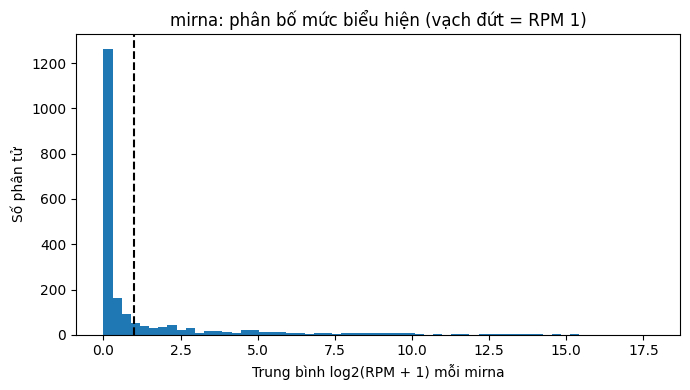

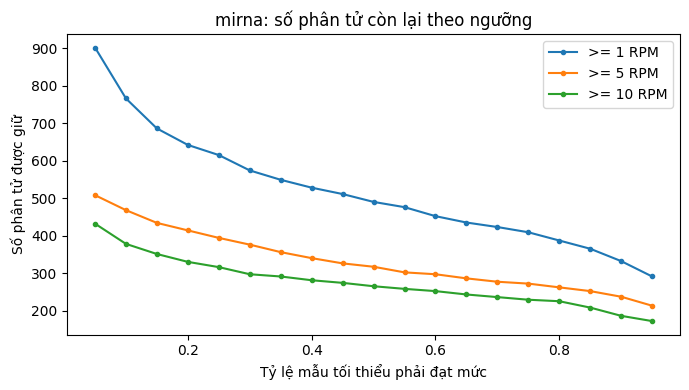

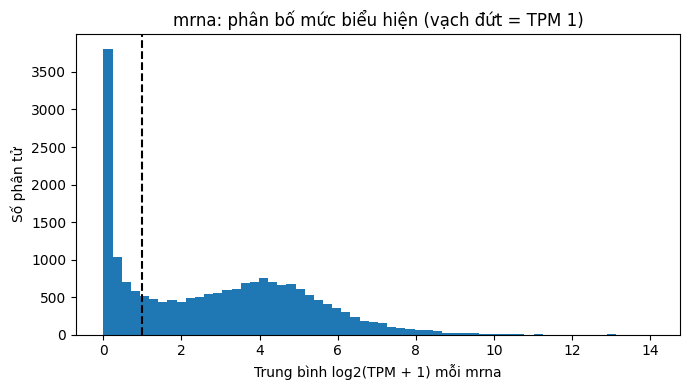

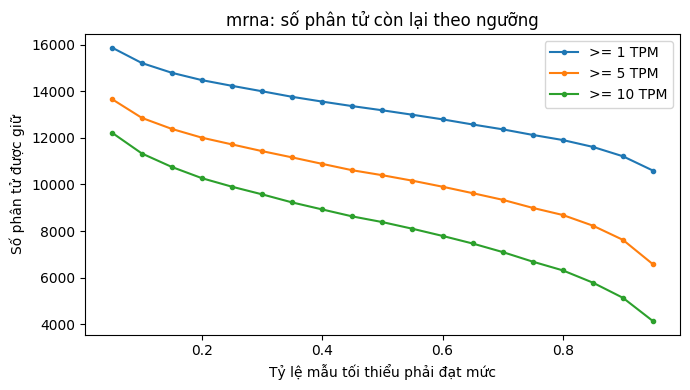

In [8]:
mir_rpm = pd.read_parquet(f"{DATA}/b5_mir_rpm.parquet")
mr_tpm  = pd.read_parquet(f"{DATA}/b5_mr_tpm.parquet")
ty_le = np.arange(0.05, 1.0, 0.05)

for loai, m, don in [("mirna", mir_rpm, "RPM"), ("mrna", mr_tpm, "TPM")]:
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(np.log2(m + 1).mean(axis=1), bins=60)
    ax.axvline(1, ls="--", c="k")
    ax.set(xlabel=f"Trung bình log2({don} + 1) mỗi {loai}", ylabel="Số phân tử",
           title=f"{loai}: phân bố mức biểu hiện (vạch đứt = {don} 1)")
    fig.tight_layout(); fig.savefig(f"{QC}/b6_{loai}_phan_bo.png", dpi=150); plt.show()

    bang = []
    fig, ax = plt.subplots(figsize=(7, 4))
    for muc in (1, 5, 10):
        so_giu = [int(((m >= muc).mean(axis=1) >= p).sum()) for p in ty_le]
        ax.plot(ty_le, so_giu, marker="o", ms=3, label=f">= {muc} {don}")
        bang += [{"muc": muc, "ty_le_mau": round(p, 2), "so_giu": s} for p, s in zip(ty_le, so_giu)]
    ax.set(xlabel="Tỷ lệ mẫu tối thiểu phải đạt mức", ylabel="Số phân tử được giữ",
           title=f"{loai}: số phân tử còn lại theo ngưỡng")
    ax.legend(); fig.tight_layout(); fig.savefig(f"{QC}/b6_{loai}_duong_giu.png", dpi=150); plt.show()
    pd.DataFrame(bang).to_csv(f"{QC}/b6_{loai}_duong_giu.csv", index=False)

## Bước 7 – Áp ngưỡng, biến đổi log2, tạo VST cho phân tích độ nhạy

In [9]:
# ĐIỀN NGƯỠNG SAU KHI XEM HÌNH Ở BƯỚC 6 (ghi lý do vào nhật ký dự án)
MUC_MIRNA_RPM = None   # ví dụ 1
TY_LE_MIRNA   = None   # ví dụ 0.2 (= 20% mẫu)
MUC_MRNA_TPM  = None   # ví dụ 1
TY_LE_MRNA    = None   # ví dụ 0.2
if None in (MUC_MIRNA_RPM, TY_LE_MIRNA, MUC_MRNA_TPM, TY_LE_MRNA):
    raise ValueError("Chưa điền ngưỡng. Xem hình ở Bước 6 rồi điền 4 giá trị ở đầu ô này.")

mir_rpm = pd.read_parquet(f"{DATA}/b5_mir_rpm.parquet")
mr_tpm  = pd.read_parquet(f"{DATA}/b5_mr_tpm.parquet")
mr_cnt  = pd.read_parquet(f"{DATA}/b5_mr_count.parquet")

giu_mir = (mir_rpm >= MUC_MIRNA_RPM).mean(axis=1) >= TY_LE_MIRNA
giu_mr  = (mr_tpm  >= MUC_MRNA_TPM).mean(axis=1)  >= TY_LE_MRNA
mir_log2 = np.log2(mir_rpm[giu_mir] + 1)
mr_log2  = np.log2(mr_tpm[giu_mr] + 1)
print(f"miRNA giữ: {giu_mir.sum()}/{len(giu_mir)} | gen giữ: {giu_mr.sum()}/{len(giu_mr)}")
mir_log2.to_parquet(f"{DATA}/b7_mir_log2rpm.parquet")
mr_log2.to_parquet(f"{DATA}/b7_mr_log2tpm.parquet")
json.dump({"MUC_MIRNA_RPM": MUC_MIRNA_RPM, "TY_LE_MIRNA": TY_LE_MIRNA,
           "MUC_MRNA_TPM": MUC_MRNA_TPM, "TY_LE_MRNA": TY_LE_MRNA},
          open(f"{DATA}/b7_nguong.json", "w"), indent=2)

# VST (chuẩn hóa cấp cohort) – chỉ dùng cho phân tích độ nhạy
try:
    from pydeseq2.dds import DeseqDataSet
    dem = mr_cnt[giu_mr].T.round().astype(int)               # pydeseq2 cần mẫu x gen
    dds = DeseqDataSet(counts=dem, metadata=pd.DataFrame({"nhom": "a"}, index=dem.index), design="~1")
    dds.vst(use_design=False)
    mr_vst = pd.DataFrame(dds.layers["vst_counts"], index=dem.index, columns=dem.columns).T
    mr_vst.to_parquet(f"{DATA}/b7_mr_vst.parquet")
    print("Đã lưu VST.")
except Exception as e:
    print("VST bằng pydeseq2 lỗi:", e, "\n-> Xem cách chạy VST bằng R trong tab hướng dẫn (bảng lỗi thường gặp).")

ValueError: Chưa điền ngưỡng. Xem hình ở Bước 6 rồi điền 4 giá trị ở đầu ô này.

## Bước 8 – Báo cáo cỡ mẫu và số sự kiện (mốc kiểm tra cuối tháng 11/2026)
Chỉ đếm. **Không** xem miRNA hay gen nào liên quan đến tái phát.

In [ ]:
ls = pd.read_csv(f"{DATA}/b5_lam_sang.csv")

bao_cao = pd.DataFrame([{
    "endpoint": ep,
    "so_benh_nhan": int(ls[ep].notna().sum()),
    "so_su_kien": int((ls[ep] == 1).sum()),
    "theo_doi_trung_vi_nam": theo_doi_trung_vi(ls[f"{ep}.time"], ls[ep]),
} for ep in ["PFI", "OS", "DFI"]])
bao_cao["so_dac_trung_toi_da_EPV10"] = bao_cao.so_su_kien // 10
print(bao_cao.to_string(index=False))
bao_cao.to_csv(f"{QC}/b8_bao_cao_su_kien.csv", index=False)
ghi("B8.1 Cohort huấn luyện cuối", len(ls))
print(pd.read_csv(F_SO_DO).to_string(index=False))

with open(f"{QC}/pip_freeze.txt", "w") as f:   # lưu phiên bản mọi gói để tái lập
    f.write(subprocess.run([sys.executable, "-m", "pip", "freeze"], capture_output=True, text=True).stdout)

## Bước 9 – METABRIC phần công khai (cBioPortal)
cBioPortal chỉ có **ER theo IHC** (`ER_IHC`). `PR_STATUS` suy từ biểu hiện gen, `HER2_STATUS` từ SNP6/biểu hiện; **không có PR_IHC, HER2_IHC**. Vì vậy định nghĩa "IHC chặt" không áp dụng được với dữ liệu công khai, chỉ dùng định nghĩa tổ hợp. Ghi rõ điều này trong phần phương pháp.

In [ ]:
# Đã có thư mục brca_metabric (giải nén sẵn) trong data/ hoặc _tam/ thì dùng luôn, không tải lại
F_TAR = f"{TAM}/brca_metabric.tar.gz"                                # file nén ~510 MB
TM = next((d for d in (f"{DATA}/brca_metabric", f"{TAM}/brca_metabric") if os.path.isdir(d)),
          f"{TAM}/brca_metabric")
if not os.path.isdir(TM):
    if not os.path.exists(F_TAR):
        with requests.get("https://datahub.assets.cbioportal.org/brca_metabric.tar.gz", stream=True, timeout=300) as r:
            r.raise_for_status()
            with open(F_TAR + ".part", "wb") as f:
                for khoi in r.iter_content(1 << 20):           # ghi từng 1 MB, không giữ cả file trong RAM
                    f.write(khoi)
        os.replace(F_TAR + ".part", F_TAR)                    # chỉ đổi tên khi tải xong
    with tarfile.open(F_TAR) as t:
        t.extractall(TAM, filter="data")
print(sorted(os.listdir(TM)))

doc_cbio = lambda ten: pd.read_csv(f"{TM}/{ten}", sep="\t", comment="#", dtype=str)
mb = doc_cbio("data_clinical_patient.txt").merge(doc_cbio("data_clinical_sample.txt"), on="PATIENT_ID")
ghi("B9.0 METABRIC có lâm sàng", len(mb))

print([c for c in mb.columns if any(k in c for k in ["ER", "PR", "HER2", "IHC", "SNP6", "STAGE", "SEX", "RFS", "OS_"])])
for c in [c for c in ["ER_IHC", "ER_STATUS", "PR_STATUS", "HER2_SNP6", "HER2_STATUS"] if c in mb.columns]:
    print(f"--- {c} ---\n{mb[c].value_counts(dropna=False).to_string()}\n")

am = lambda s: s.fillna("").str.lower().str.startswith("neg")
co_kq = lambda s: s.fillna("").str.lower().str[:3].isin(["pos", "neg"])   # ER_IHC có giá trị "Positve" (lỗi gõ gốc)
du = co_kq(mb.ER_IHC) & co_kq(mb.PR_STATUS) & co_kq(mb.HER2_STATUS)
mb = mb[du].copy()
ghi("B9.1 Có đủ ER_IHC, PR_STATUS, HER2_STATUS", len(mb), f"loại {(~du).sum()} ca thiếu")
# Định nghĩa 1 – IHC chặt: cần IHC cho cả ER, PR, HER2
co_ihc_du = all(c in mb.columns for c in ["ER_IHC", "PR_IHC", "HER2_IHC"])
mb["tnbc_ihc_chat"] = (am(mb.ER_IHC) & am(mb.PR_IHC) & am(mb.HER2_IHC)) if co_ihc_du else False
if not co_ihc_du:
    print("METABRIC không có IHC cho cả 3 thụ thể: định nghĩa chặt không áp dụng được.")
# Định nghĩa 2 – tổ hợp: ER theo IHC; PR, HER2 theo trường trạng thái có sẵn
mb["tnbc_to_hop"] = am(mb.ER_IHC) & am(mb.PR_STATUS) & am(mb.HER2_STATUS)
ghi("B9.2 TNBC – định nghĩa IHC chặt", int(mb.tnbc_ihc_chat.sum()))
ghi("B9.3 TNBC – định nghĩa tổ hợp", int(mb.tnbc_to_hop.sum()))

# Tiêu chí loại tương ứng (tân bổ trợ: METABRIC không có thông tin, ghi rõ trong khóa luận)
if "SEX" in mb.columns:
    mb = mb[~mb.SEX.str.upper().eq("MALE")]
if "TUMOR_STAGE" in mb.columns:
    mb = mb[pd.to_numeric(mb.TUMOR_STAGE, errors="coerce") != 4]
mbt = mb[mb.tnbc_to_hop | mb.tnbc_ihc_chat].copy()
trang_thai = lambda s: pd.to_numeric(s.str[:1], errors="coerce")       # "1:Recurred" -> 1
mbt["RFS"], mbt["OS"] = trang_thai(mbt.RFS_STATUS), trang_thai(mbt.OS_STATUS)
ghi("B9.4 METABRIC TNBC sau tiêu chí loại", len(mbt), "hợp của 2 định nghĩa")

# mRNA microarray: ĐÃ ở thang log2 do nhóm tác giả chuẩn hóa, không lấy log thêm
f_mr = [f for f in os.listdir(TM) if f.startswith("data_mrna") and f.endswith("microarray.txt") and "zscore" not in f][0]
print("File mRNA dùng:", f_mr)
mb_mr = pd.read_csv(f"{TM}/{f_mr}", sep="\t")
cot_mau = [s for s in mbt.SAMPLE_ID if s in mb_mr.columns]
mb_mr = mb_mr.dropna(subset=["Hugo_Symbol"])
print("Dòng trùng tên gen được gộp (trung bình):", mb_mr.Hugo_Symbol.duplicated().sum())
mb_mr = mb_mr[["Hugo_Symbol"] + cot_mau].groupby("Hugo_Symbol").mean()   # gen x mẫu, thang log2
ghi("B9.5 METABRIC TNBC có mRNA", len(cot_mau))

mbc = mbt[mbt.SAMPLE_ID.isin(cot_mau)]
bao_cao_mb = pd.DataFrame([{
    "endpoint": ep,
    "so_benh_nhan": int(mbc[ep].notna().sum()),
    "so_su_kien": int((mbc[ep] == 1).sum()),
    "theo_doi_trung_vi_nam": theo_doi_trung_vi(pd.to_numeric(mbc[f"{ep}_MONTHS"]) * 365.25 / 12, mbc[ep]),
} for ep in ["RFS", "OS"]])
print(bao_cao_mb.to_string(index=False))
bao_cao_mb.to_csv(f"{QC}/b9_metabric_bao_cao_su_kien.csv", index=False)
mbt.to_csv(f"{DATA}/b9_metabric_lam_sang.csv", index=False)
mb_mr.to_parquet(f"{DATA}/b9_metabric_mrna.parquet")

## Bước 10 – METABRIC miRNA (tải thủ công qua Synapse)
Làm theo tab hướng dẫn: tạo tài khoản Synapse, tìm dữ liệu miRNA METABRIC, đọc điều kiện sử dụng. Nếu tải được, đặt file vào `data/` với tên `metabric_mirna_goc.txt`, rồi chạy ô dưới.

In [ ]:
F_MB_MIR = f"{DATA}/metabric_mirna_goc.txt"
if os.path.exists(F_MB_MIR):
    mb_mir = pd.read_csv(F_MB_MIR, sep="\t")
    print(mb_mir.shape); print(mb_mir.iloc[:5, :5])
    print("Đã có file miRNA METABRIC. Kiểm tra cấu trúc trước khi ghép (xem tab hướng dẫn).")
else:
    print("Chưa có miRNA METABRIC. Kiểm chứng đặc trưng cặp sẽ theo phương án dự phòng ở mục 8 của đề cương.")